<a href="https://colab.research.google.com/github/psh-computer/Machine-Learning/blob/main/day03_0_vision_pytorch_basic_student_v1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyTorch 비전 기초 -- PIL/transforms/DataLoader/Conv/pretrained 모델

학습 목표: SimCLR 구현에 필요한 비전 계열 PyTorch API를 직접 실행하며 이해한다. Day02의 텍스트 PyTorch 위에서, 이미지 도메인으로 확장하는 것이 이 노트북의 목표이다.

학습 내용:

1. PIL Image -- 이미지 로딩, 검사,(H,W,C) 형태 이해
2. HWC vs CHW -- PyTorch 차원 순서의 핵심 차이
3. transforms -- Resize/ToTensor/Normalize 단계별 직접 체험
4. 역정규화 -- 시각화를 위한 필수 패턴
5. CustomDataset + DataLoader -- 이미지 배치 처리 파이프라인
6. Convolution -- Conv2d로 특징 추출 직접 체험
7. pretrained ResNet-18 -- 로딩 / layer-by-layer shape 추적 / fc 제거
8. BatchNorm + train/eval 모드 -- BN 동작 방식과 모드 차이
9. nn.Sequential + Projection Head 뼈대 -- SimCLR 모델 구성 미리보기
10. 텐서 연산 미니 실습 -- cat / eye / CE / topk.mode / TensorDataset / 체크포인트 / Adam / AMP

사용 기술 : PyTorch 2.x, torchvision, Pillow, matplotlib, Colab T4

In [ ]:
## 재현성: 보조 패키지 버전 고정 (torch/torchvision은 Colab. 런타임 기본 사용)
!pip install -q pillow==10.3.0 matplotlib==3.8.4 # torch==2.2.0 torchvision==0.17.0
# 한글 폰트
!apt-get install -y fonts-nanum > /dev/null 2>&1
print('패키지 설치 완료')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 MB 17.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
패키지 설치 완료


## 세션 다시 시작

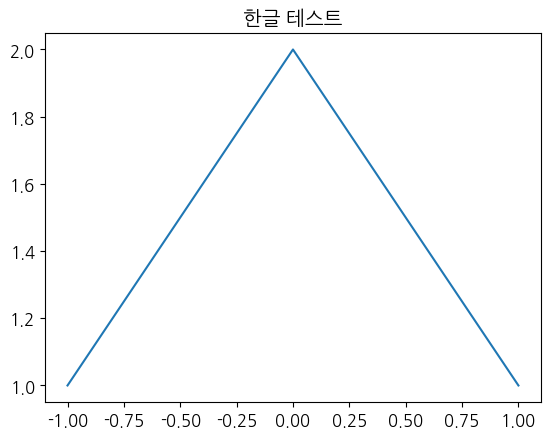

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 설치된 나눔길 찾기 및 캐시 업데이트
fe = fm.FontEntry(
    fname=r'/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
    name='NanumGothic'
)

fm.fontManager.ttflist.insert(0, fe)
plt.rcParams.update({'font.size': 12, 'font.family': 'NanumGothic'})

plt.title('한글 테스트')
plt.plot([-1, 0, 1], [1, 2, 1])
plt.show()

In [ ]:
!python -V

Python 3.13.16


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print(f'torch       : {torch.__version__}')
print(f'torchvision : {torchvision.__version__}')
print(f'Pillow      : {Image.__version__}')
print(f'numpy       : {np.__version__}')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'device      : {device}')

torch       : 2.11.0+cpu
torchvision : 0.26.0+cpu
Pillow      : 11.3.0
numpy       : 2.1.3
device      : cpu


PIL Image 기본 정보
 타입 : <class 'PIL.Image.Image'>
 크기 : (96, 96) <-- (Width, Height 순서 주의)
 모드 : RGB <-- RGB = 3채널 컬러

 [numpy 변환 후]
  shape : (96, 96, 3) <-- (Height, Width, Channel)
  dtype : uint8
  값 범위 : [0, 255]

 img.size = (96, 96)      <-- PIL은 (Width, Height)
 arr.shape = (96, 96, 3)      <-- numpy/matplotlib은 (Height, Width, Channel)


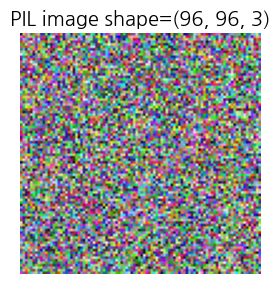

In [ ]:
"""
PIL(Pillow): Python 에서 이미지를 다루는 표준 라이브러리.
torchvision의 transforms 파이프라인은 PIL Imag를 입력으로 받는다.

핵심 특성:
  - 픽셀 값 범위: uint8, [0, 255]
  - 차원 순서: (Height, Width, Channel) - HWC
  - mode : 'RGB'(컬러 3채널), 'L'(흑백1채널), 'RGBA'(투명도 포함 4채널)

주의: img.size 는 (W, H) 순서 - numpy의 shape(H, W, C)와 다르다.
"""

# 랜덤 numpy 배열로 가상 이미지 생성 (실제 파일 없이 실습 가능)
img_np = np.random.randint(0, 256, (96, 96, 3), dtype=np.uint8) # np.uint8 = 0~255
img = Image.fromarray(img_np) # numpy -> PIL Image

print('PIL Image 기본 정보')
print(f' 타입 : {type(img)}')
print(f' 크기 : {img.size} <-- (Width, Height 순서 주의)')
print(f' 모드 : {img.mode} <-- RGB = 3채널 컬러')

# PIL --> numpy 배열로 변환
arr = np.array(img)
print(f'\n [numpy 변환 후]')
print(f'  shape : {arr.shape} <-- (Height, Width, Channel)')
print(f'  dtype : {arr.dtype}')
print(f'  값 범위 : [{arr.min()}, {arr.max()}]')

print(f'\n img.size = {img.size}      <-- PIL은 (Width, Height)')
print(f' arr.shape = {arr.shape}      <-- numpy/matplotlib은 (Height, Width, Channel)')

# 간단 시각화
plt.figure(figsize=(3, 3))
plt.imshow(img)
plt.title(f'PIL image shape={arr.shape}')
plt.axis('off')
plt.tight_layout()
plt.show()

## S2. HWC vs CHW - PyTorch 차원 순서의 핵심 차이

In [ ]:
"""
이미지 차원 순서에는 두 가지 표준이 있다:

  HWC (Height, Width, Channel):
    - PIL, numpy, matplotlib 사용
    - 예: (96, 96, 3)

  CHW (Channel, Height, Width):
    - PyTorch 텐서, nn.Conv2d 입력 필요
    - 예: (3, 96, 96)

transforms.ToTensor()는 HWC -> CHW 변환을 자동으로 수행한다.
이 사실을 모르면 shape 관련 에러가 계속 발생한다.
"""

import torchvision.transforms as transforms

H, W, C = 96, 96, 3

# numpy HWC 형태
np_img = np.random.randint(0, 256, (H, W, C), dtype=np.uint8)
print(f'numpy 원본 shape: {np_img.shape} <-- HWC')

# 방법 1: 수동 변환 (permute)
tensor_manual = torch.from_numpy(np_img.copy()).permute(2, 0, 1)/float() / 255.0 # 0.0~1.0
print(f'수동 변환 (HWC -> CHW): {tensor_manual.shape} <-- CHW')
print(f'permute(2,0,1): 채널(2번째)을 앞으로 이동')

# 방법 2: transforms.ToTensor() 자동 변환 (0-1로 정규화)
pil_img = Image.fromarray(np_img)
tensor_auto = transforms.ToTensor()(pil_img)
print(f'\n ToTensor() 자동 변환: {tensor_auto.shape} <-- CHW 자동')
print(f'dtype : {tensor_auto.dtype}')
print(f' 값 범위 : [{tensor_auto.min():.3f}, {tensor_auto.max():.3f}]')

# 시각화 시에는 다시 HWC로 돌려야 함
tensor_for_plot = tensor_auto.permute(1, 2, 0).numpy() # CHW -> HWC
print(f'\n 시각화용 역변환 : {tensor_for_plot.shape} <-- permute(1,2,0)로 HWC 복원')

print('\n[정리]')
print('PIL/numpy -> 모델 입력 : HWC -> ToTensor() -> CHW')
print('모델 출력 -> 시각화      : CHW -> permute(1,2,0) -> HWC')

numpy 원본 shape: (96, 96, 3) <-- HWC
수동 변환 (HWC -> CHW): torch.Size([3, 96, 96]) <-- CHW
permute(2,0,1): 채널(2번째)을 앞으로 이동

 ToTensor() 자동 변환: torch.Size([3, 96, 96]) <-- CHW 자동
dtype : torch.float32
 값 범위 : [0.000, 1.000]

 시각화용 역변환 : (96, 96, 3) <-- permute(1,2,0)로 HWC 복원

[정리]
PIL/numpy -> 모델 입력 : HWC -> ToTensor() -> CHW
모델 출력 -> 시각화      : CHW -> permute(1,2,0) -> HWC


## S3. transforms -- Resize / ToTensor / Normalize 단계별 체험

In [ ]:
"""
transforms.Resize(size) : PIL Image 크기(배율) 조정
  - 입력 : PIL Image
  - 출력 : PIL Image (크기만 변경)
  - 정수 : 짧은 쪽 기준 리사이즈 (비율 유지)
  - (H, W) 튜플 : 정확한 크기로 강제 리사이즈
"""

pil_img = Image.fromarray(np.random.randint(0, 256, (200, 150, 3), dtype=np.uint8))
print(f'Resize 전 size  : {pil_img.size} <-- (W, H) = (150,200)')

# 정수 - 짧은 쪽 기준
resized_int = transforms.Resize(96)(pil_img)
print(f'Resize(96) 후   : {resized_int.size} <-- 짧은 쪽(150->96), 비율 유지')

# 튜플 (H, W) - 정확한 크기
resized_sq = transforms.Resize((96, 96))(pil_img)
print(f'Resize(96, 96)후: {resized_sq.size} <-- 정확히 96X96')

Resize 전 size  : (150, 200) <-- (W, H) = (150,200)
Resize(96) 후   : (96, 128) <-- 짧은 쪽(150->96), 비율 유지
Resize(96, 96)후: (96, 96) <-- 정확히 96X96


In [ ]:
"""
transforms.ToTensor() : PIL Image -> PyTorch Tensor 2가지를 동시 수행

  1. 차원 순서 변경 : (H, W, C) -> (C, H, W)
  2. 값 범위 변환 : uint8 [0, 255] -> float32 [0.0, 1.0] ( /255 자동)

이 두 가지를 한 줄로 처리한다는 점이 중요하다.
"""

pil_img = Image.fromarray(np.random.randint(0, 256, (96, 96, 3), dtype=np.uint8))
arr = np.array(pil_img)

print('[ToTensor 전]')
print(f' PIL Shape : {arr.shape} <-- HWC')
print(f' dtype     : {arr.dtype}')
print(f' 값 범위     : [{arr.min()}, {arr.max()}]')

tensor = transforms.ToTensor()(pil_img)

print('[ToTensor 후]')
print(f' Tensor Shape : {tensor.shape} <-- CHW (자동 변환)')
print(f'  dtype       : {tensor.dtype}')
print(f'  값 범위       : [{tensor.min():.3f}, {tensor.max():.3f}]')
print(f'\n[요약]')
print(f' HWC {arr.shape} --> CHW {tensor.shape}')
print(f' uint8 [0, 255] --> float32 [0, 1]')


[ToTensor 전]
 PIL Shape : (96, 96, 3) <-- HWC
 dtype     : uint8
 값 범위     : [0, 255]
[ToTensor 후]
 Tensor Shape : torch.Size([3, 96, 96]) <-- CHW (자동 변환)
  dtype       : torch.float32
  값 범위       : [0.000, 1.000]

[요약]
 HWC (96, 96, 3) --> CHW torch.Size([3, 96, 96])
 uint8 [0, 255] --> float32 [0, 1]


## 이미지 채널별 표준화

표준화(Standardization) 공식인 (z=(x-평균)/표준편차)를 사용하기 떄문입니다. 평균을 빼면: 데이터의 중심이 0이 됩니다.

표준편차로 나누면: 데이터가 퍼진 정도가 1이 됩니다.

통계적 분포: 통계적으로 데이터의 약 96%는 표준편차의 2배수(+-2a) 안에 들어옵니다. 그래서 결과값이 대략 -2에서 2 사이에 놓이게 되는 것입니다.


In [ ]:
"""
transforms.Normalize(mean, std) : 채널별 표준화

  공식 : output[c] = (input[c] - mean[c] / std[c])

ImageNet 통계값 (대부분의 비전 모델 표준):
  mean = [0.485, 0.456, 0.406] <-- R, G, B 채널 평균
  std  = [0.229, 0.224, 0.225] <-- R, G, B 채널 표준편차

정규화 후 값 범위 : [0, 1] -> 약 [-2, 2]
정규화된 탠서를 plt.imshow()에 직접 넣으면 이상한 그림이 나온다.
  시각화 전에는 반드시 역정규화(un-normalize)가 필요하다.
"""

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

pil_img = Image.fromarray(np.random.randint(0, 256, (96, 96, 3), dtype=np.uint8))
tensor = transforms.ToTensor()(pil_img)

print('[Normalize 전]')
print(f' 값 범위 : [{tensor.min():.3f}, {tensor.max():.3f}]')

normalized = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)(tensor)

print('[Normalize 후]')
print(f' 값 범위 : [{normalized.min():.3f}, {normalized.max():.3f}]')
print(f' shape : {normalized.shape} <-- shape은 변하지 않음')

print(f'\n[채널별 통계 비교]')
for c, name in enumerate(['R', 'G', 'B']):
  before = tensor[c].mean().item()
  after  = normalized[c].mean().item()
  print(f' 채널{name}: before mean={before:.3f} --> after mean={after:.4f} (=0 목표)')


[Normalize 전]
 값 범위 : [0.000, 1.000]
[Normalize 후]
 값 범위 : [-2.118, 2.640]
 shape : torch.Size([3, 96, 96]) <-- shape은 변하지 않음

[채널별 통계 비교]
 채널R: before mean=0.503 --> after mean=0.0776 (=0 목표)
 채널G: before mean=0.499 --> after mean=0.1929 (=0 목표)
 채널B: before mean=0.498 --> after mean=0.4078 (=0 목표)


## 왜 역표준화가 필요한가

transforms.Normalize는 모델 학습을 위해 픽셀값을 평균 0, 표준편차 1근처로 변환합니다. 이 상태의 텐서를 그대로 imshow에 넣으면 음수 값이나 1 초과 값이 생겨 색상이 완전히 깨집니다. 사람 눈에 보이는 이미지로 복원하려면 표준화의 역산이 필요합니다.

표준화 후 값 범위  : [-2.118, 2.640]
역표준화 후 값 범위 : [0.000, 1.000]


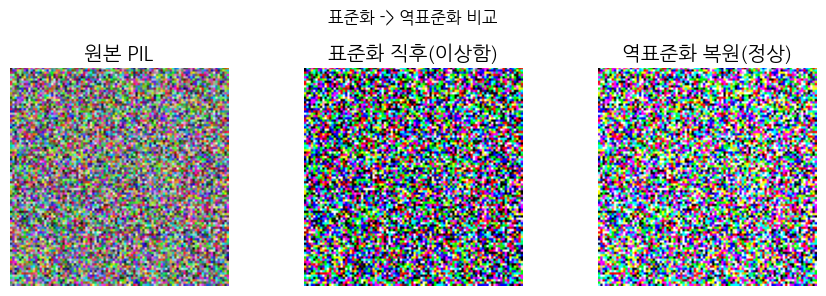

역표준화 없이 시각화하면 이상한 그림이 나온다는 것을 직접 확인


In [ ]:
"""
역표준화 (Un-normalize): 시각화를 위한 필수 패턴

  Normalize의 연산: 원본[c] = 표준화[c] * std[c] + mean[c]

SimCLR 실습에서 증강된 두 뷰를 시각화할 때 반드시 사용한다.
이 패턴을 모르면 증강 결과를 확인할 수 없다.
"""

IMAGENET_MEAN_T = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1) # (3, 1, 1): 채널별 브로드캐스팅
IMAGENET_STD_T = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def unnormalize(tensor):
  """표준화된 텐서(CHW) --> [0, 1] 복원 후 (HWC) numpy 변환. 시각화용."""
  img = tensor.cpu() + IMAGENET_MEAN_T # 역산
  img = img.clamp(0, 1)                # 범위 강제(=clip), 특정 최소/최대 범위 내로 가두는 역할
  # permute: 텐서의 차원(축) 순서를 사용자가 원하는 대로 재배치
  return img.permute(1, 2, 0).numpy()  # CHW --> HWC

# 전체 파이프 라인: PIL -> Compose -> 역표준화 -> 시각화
full_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

pil_img = Image.fromarray(np.random.randint(0, 256, (96, 96, 3), dtype=np.uint8))
t = full_transform(pil_img)
recovered = unnormalize(t)

print(f'표준화 후 값 범위  : [{t.min():.3f}, {t.max():.3f}]')
print(f'역표준화 후 값 범위 : [{recovered.min():.3f}, {recovered.max():.3f}]')

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(pil_img); axes[0].set_title('원본 PIL')
axes[1].imshow(t.permute(1,2,0).clamp(0,1).numpy()); axes[1].set_title('표준화 직후(이상함)')
axes[2].imshow(recovered); axes[2].set_title('역표준화 복원(정상)')

for ax in axes: ax.axis('off')
plt.suptitle('표준화 -> 역표준화 비교', fontsize=12)
plt.tight_layout()
plt.show()
print('역표준화 없이 시각화하면 이상한 그림이 나온다는 것을 직접 확인')

## Convolution - 특징 추출을 눈으로 확인

입력 이미지 shape: torch.Size([1, 3, 96, 96]) <-- (Batch=1, C=3, H=96, W=96)

 Conv2d 통과 후 : torch.Size([1, 8, 96, 96])  <-- (Batch=1, C_out=8, H=96, W=96)
 파라미터 수       : 224 (3X8X3X3 + bias 8)


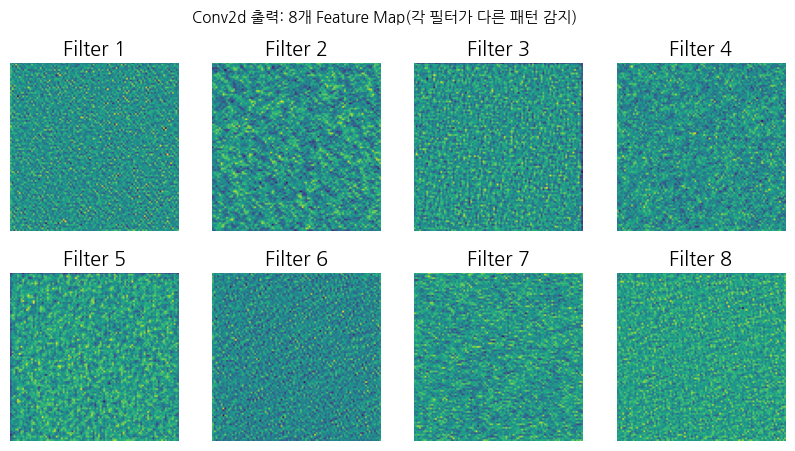

In [ ]:
"""
nn.Conv2d(in_channels, out_channels, kernel_size): 2D 합성곱 레이어

  in_channels : 입력 채널 수 (RGB 이미지 = 3)
  out_channels: 출력 채널 수 = 학습할 필터(특징 감지기) 수
  kernel_size : 필터 크기 (예: 3 -> 3X3)

출력 shape:
  입력: (B, C_in, H, W)
  출력: (B, C_OUT, H', W') - H', W'는 패딩에 따라 결정

ResNet-18 내부도 이 Conv2d가 수십 개 쌓인 구조다.
"""

# 단일 이미지 (배치 차원 추가: 1, 3, 96, 96)
img_np = np.random.randint(0, 256, (96, 96, 3), dtype=np.uint8)
img_tensor = transforms.ToTensor()(Image.fromarray(img_np)).unsqueeze(0)  # unsqueeze(0): 첫 번쨰 인덱스에 1차원 추가, (1, 3, 96, 96)
print(f'입력 이미지 shape: {img_tensor.shape} <-- (Batch=1, C=3, H=96, W=96)')

# Conv2d: 3채널 입력 --> 8채널 출력 (8가지 패턴 감지)
conv = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, padding=1)
with torch.no_grad():
  feature_maps = conv(img_tensor) # (1, 8, 96, 96)

print(f'\n Conv2d 통과 후 : {feature_maps.shape}  <-- (Batch=1, C_out=8, H=96, W=96)')
print(f' 파라미터 수       : {sum(p.numel() for p in conv.parameters())} (3X8X3X3 + bias 8)')

# 8개 feature map 시각화
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes = axes.flatten()
for i in range(8):
  fmap = feature_maps[0, i].numpy() # i번째 필터의 출력
  axes[i].imshow(fmap, cmap='viridis')
  axes[i].set_title(f'Filter {i+1}')
  axes[i].axis('off')
plt.suptitle('Conv2d 출력: 8개 Feature Map(각 필터가 다른 패턴 감지)', fontsize=11)
plt.tight_layout
plt.show()

# CNN 복습

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# CIFAR-10: 32 X 32 컬러 이미지, 10개 클래스 (비행기, 자동차, 새, 고양이 등)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean = (0.5, 0.5, 0.5),   # 픽셀값 [0, 1] --> [-1, 1]
                         std = (0.5, 0.5, 0.5))
])

train_ds=  datasets.CIFAR10('./data', train=True, download=True, transform=transform)
test_ds=  datasets.CIFAR10('./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)

#------------------------------------ 데이터 Shape 확인 -------------------------------------------
imgs, labels = next(iter(train_loader))
print(f'입력 텐서 shape : {img.shape}') # (64, 3, 32, 32) = (배치, 채널, H, W)
print(f'레이블 shape    : {labels.shape}') # (64,)
print(f'클래스 목록      : {train_ds.classes}')


 57%|█████▋    | 96.6M/170M [24:23<22:27, 54.8kB/s]

In [ ]:
class SimpleCNN(nn.Module):
  """
  구조: Conv -> BN -> ReLU -> Pool 블록 3개 + FC 분류기

  일력: (B, 3, 32, 32)
  Block1: Conv(3->32) + Pool -> (B, 32, 16, 16)
  Block2: Conv(32->64) + Pool -> (B, 64, 8, 8)
  Block3: Conv(64->128) + Pool -> (B, 128, 4, 4)
  Flatten: (B, 2048)
  FC: 2048 -> 256 -> 10
  """

  def __init__(self, num_classes=10):
    super().__init__()
    #----------특징 추출부---------------
    self.block1 = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, padding=1), # 채널 3->32, 크기 유지
        nn.BatchNorm2d(32),                         # 학습 안정화
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),                            # 32 X 32 -> 16 X 16
    )

    self.block2 = nn.Sequential(
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),                            # 16 X 16 -> 8 X 8
    )

    self.block3 = nn.Sequential(
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),                            # 8 X 8 -> 4 X 4
    )

    #--------- 분류기 ----------------------
    self.classifier = nn.Sequential(
        nn.Flatten(),                               # (B, 128, 4, 4) -> (B, 2048)
        nn.Linear(128*4*4, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.4),                            # 과적합 방지
        nn.Linear(256, num_classes)
    )

  def forward(self, x):
    x = self.block1(x)                              # (B, 32, 16, 16)
    x = self.block2(x)                              # (B, 64, 8, 8)
    x = self.block3(x)                              # (B, 128, 4, 4)
    x = self.classifier(x)                          # (B, 10)
    return x

#------------------ 구조 및 파라미터 수 확인 -------------------------
model = SimpleCNN()
dummy = torch.randn(2, 3, 32, 32)                   # 가짜 배치로 shape 테스트
print(f'입력 --> 출력: {dummy.shape} --> {model(dummy).shape}')

total_params = sum(p.numel() for p in model.parameters())
print(f'총 파라미터 : {total_params:,}개')



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. 학습 환경 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN(num_classes=10).to(device)

# 2. Loss 함수와 Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3. 학습 설정
num_epochs = 10

for epoch in range(num_epochs):

    # ---------------- Training ----------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Gradient 초기화
        optimizer.zero_grad()

        # Forward: 예측
        outputs = model(images)

        # Loss 계산
        loss = criterion(outputs, labels)

        # Backward: Gradient 계산
        loss.backward()

        # 가중치 업데이트
        optimizer.step()

        # 통계 기록
        batch_size = labels.size(0)
        train_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    avg_train_loss = train_loss / train_total
    train_acc = 100 * train_correct / train_total

    # ---------------- Evaluation ----------------
    model.eval()

    test_loss = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            test_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            test_correct += (predictions == labels).sum().item()
            test_total += batch_size

    avg_test_loss = test_loss / test_total
    test_acc = 100 * test_correct / test_total

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"| Train Loss: {avg_train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Test Loss: {avg_test_loss:.4f} "
        f"| Test Acc: {test_acc:.2f}%"
    )

## S6. pretrained ResNet-18 - 로딩 / 구조 확인 / fc 제거

In [ ]:
"""
torchvision.models.resnet18(pretrained=True)
  - ImagNet 120만 장으로 사전 학습된 ResNet-18 가중치를 자동 다운로드
  - 기본 출력 : (B, 1000) - ImageNet 1000 클래스 분류
  - 가중치 크기 : 약 44.7MB

SimCLR에서는 분류(1000개) 대신 표현 추출(512차원)이 목적이므로
마지막 fc layer를 제거한다.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 경고 메시지 억제 (pretrained 파라미터 deprecated 경고)
import warnings
warnings.filterwarnings('ignore')

backbone = models.resnet18(pretrained=True)
backbone.eval()

print('ResNet-18 구조 요약')
# 최상위 레이어 이름만 출력
for name, module in backbone.named_children():
  parmas = sum(p.numel() for p in module.parameters())
  print(f'{name:12s}: {type(module).__name__:20s} 파라미터 {parmas:,}')

total = sum(p.numel() for p in backbone.parameters())
print(f'\n 전체 파라미터 : {total:,} (약 {total/1e6:.1f}M)')

ResNet-18 구조 요약
conv1       : Conv2d               파라미터 9,408
bn1         : BatchNorm2d          파라미터 128
relu        : ReLU                 파라미터 0
maxpool     : MaxPool2d            파라미터 0
layer1      : Sequential           파라미터 147,968
layer2      : Sequential           파라미터 525,568
layer3      : Sequential           파라미터 2,099,712
layer4      : Sequential           파라미터 8,393,728
avgpool     : AdaptiveAvgPool2d    파라미터 0
fc          : Linear               파라미터 513,000

 전체 파라미터 : 11,689,512 (약 11.7M)


# 텐서 연산 실습 - NT-Xent / AMP

실습 코드에서는 이미지가 아니라 작은 숫자 텐서로 손실.평가를 계산한다.

In [ ]:
"""
SB-1. torch.cat / torch.arrange / torch.eye / masked_fill / @ / F.cross_entropy

  NT-Xent의 핵심은 (2B, D) 텐서 z에 대해 sim = z @ z.T / temperature 를 만든 뒤,
  대각선을 -inf로 막고, corss_entropy로 "positive 위치"를 맞추는 것이다.
"""

B, D = 2, 4
tau = 0.5

# view 두 벌을 흉내: (B, D) - 실제로는 SimCLRNet(view1), SimCLRNET(view2)
torch.manual_seed(0)
z1 = F.normalize(torch.randn(B, D), dim=1)
z2 = F.normalize(torch.randn(B, D), dim=1)

print(f'z1 shape : {z1.shape} # (B, D)')
print(f'z2 shape : {z2.shape} # (B, D)')


# Step1 : batch 차원(dim=0)으로 이어붙이기 -> (2B, D)
z = torch.cat([z1, z2], dim=0)
print(f'\n[cat] z = cat([z1, z2]), dim - 0 --> {z.shape}  # (2B, D) = (4, 4)')

# Step2 : cosine similarity 행렬 (L2 정규화된 z이면 내적 = cosine)
sim = z @ z.T / tau   # (2B, 2B)
print(f'[matmul] sim = z @ z.T / tau --> {sim.shape}  # (2B, 2B)')

# Step3 : 자기 자신과의 유사도는 softmax에서 항상 최대 --> inf로 제거
mask = torch.eye(2*B, dtype=torch.bool)   # (2B, 2B) 대각 True
print('mask:', mask)
sim_masked = sim.masked_fill(mask, float('-inf'))
print(f'[eye+masked_fill] 대각 제거 후 sim[0, 0] = {sim_masked[0, 0]} (should be -inf)')

# Step4 : positive 인덱스 - z1_i의 짝은 z2_1 --> 인덱스 i+B
pos_idx = torch.cat([torch.arange(B, 2*B), torch.arange(B)])
print(f'\n [arange+cat] pos_idx = {pos_idx.tolist()}')
print(" 의미: 행이(z1_0)의 정답 열=2(z2_0), 행 1 -> 3, 행2 (z2_0)->0(z2_0), 행 3->1")

# Step5 : 행마다 하나의 정답 클래스를 고르는 corss_entropy
loss = F.cross_entropy(sim_masked, pos_idx)
print(f'\n [cross_entropy] NT-Xent 스타일 loss = {loss.item():.4f}')

import math
print(f'랜덤에 가까울 때 기댓값 생략 log(2B-1) = log({2*B-1}) = {math.log(2*B-1):.4f}')
print('SB-1완료 -ntxent_loss와 동일한 연산을 B*2로 축소 실행')

z1 shape : torch.Size([2, 4]) # (B, D)
z2 shape : torch.Size([2, 4]) # (B, D)

[cat] z = cat([z1, z2]), dim - 0 --> torch.Size([4, 4])  # (2B, D) = (4, 4)
[matmul] sim = z @ z.T / tau --> torch.Size([4, 4])  # (2B, 2B)
mask: tensor([[ True, False, False, False],
        [False,  True, False, False],
        [False, False,  True, False],
        [False, False, False,  True]])
[eye+masked_fill] 대각 제거 후 sim[0, 0] = -inf (should be -inf)

 [arange+cat] pos_idx = [2, 3, 0, 1]
 의미: 행이(z1_0)의 정답 열=2(z2_0), 행 1 -> 3, 행2 (z2_0)->0(z2_0), 행 3->1

 [cross_entropy] NT-Xent 스타일 loss = 1.6590
랜덤에 가까울 때 기댓값 생략 log(2B-1) = log(3) = 1.0986
SB-1완료 -ntxent_loss와 동일한 연산을 B*2로 축소 실행


In [ ]:
"""
SB-3, TensorDataset / torch.save . load / Adam / AMP(개념만)

  Linear Probe에서는 이미지 대신 (feature, label) 텐서만 DataLoader에 넣는다.
  형태만 익혀보자

"""

import os
from torch.utils.data import TensorDataset, DataLoader

# feature / label을 메모리에 올려 소형 Dataset 만들기
feats = torch.randn(32, 512)    # (N, 512) - encoder 출력을 흉내
lbls  = torch.randint(0, 10, (32, ))
ds    = TensorDataset(feats, lbls)
loader= DataLoader(ds, batch_size=9, shuffle = True)

xb, yb = next(iter(loader))
print(f'TensorDataset 배치: xb {xb.shape}, yb {yb.shape}   # (batch, 512), (batch)')

# 체크포인트: state_dict만 저장하는 패턴 (가중치만 필요할 때)
tiny = nn.Linear(4, 2)
ckpt_path = '_day03_0_tiny_ckpt_demp.pth'
torch.save(tiny.state_dict(), ckpt_path)
loaded = torch.load(ckpt_path, map_location='cpu')
tiny2 = nn.Linear(4, 2)
tiny2.load_state_dict(loaded)
print(f'\n[save/load] {ckpt_path} 저장 후 load_state_dict로 복원 OK')
os.remove(ckpt_path)

# AdamW : SimCLR에서 쓰는 옵티마이저 (한 스텝만)
w = nn.Parameter(torch.randn(3, 3))
opt = torch.optim.AdamW([w], lr=1e-3, weight_decay=1e-4)
loss = w.sum()
opt.zero_grad()
loss.backward()
opt.step()
print(f'[AdamW] 한 스텝 backward+step 완료 (SimCLR과 동일 클래스)')

# AMP: CUDA 있을 때만 (CPU에서는 건너뜀)
if torch.cuda.is_available():
  dev = torch.device('cuda')
  m = nn.Linear(8, 4).to(dev)
  x = torch.randn(4, 8, device=dev)

  # 1. GradScaler 한 번 생성
  scaler = torch.amp.GradScaler('cuda')
  opt_m = torch.optim.AdamW(m.parameters(), lr=1e-3)
  opt_m.zero_grad()

  # 2. forward는 autocast 안에서
  with torch.amp.autocast('cuda'):
    y = m(x)
    L = y.sum()

  # 3. loss 스케일 업 후 backward
  scaler.scale(L).backward()

  # 4. 스케일 다운 후 optimizer step
  scaler.step(opt_m)

  # 5. 다음 스텝 스케일 조정
  scaler.update()
  print('[AMP] autocast + GradScaler 한 스텝 완료')
else:
  print('[AMP] CUDA 없음 - Colab T4에서 다시 실행하면 AMP 셀이 동작한다.')

TensorDataset 배치: xb torch.Size([9, 512]), yb torch.Size([9])   # (batch, 512), (batch)

[save/load] _day03_0_tiny_ckpt_demp.pth 저장 후 load_state_dict로 복원 OK
[AdamW] 한 스텝 backward+step 완료 (SimCLR과 동일 클래스)
[AMP] autocast + GradScaler 한 스텝 완료
